In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
SEED = 42
IMG_SIZE = (160, 160)  # Smaller input for CPU efficiency
BATCH_SIZE = 16
EPOCHS = 8

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR if (CURRENT_DIR / "dataset").exists()
    else CURRENT_DIR.parent
)

DATASET_PATH = PROJECT_ROOT / "dataset"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

for folder in [MODELS_DIR, REPORTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Input size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Project root:", PROJECT_ROOT)

TensorFlow: 2.21.0
Input size: (160, 160)
Batch size: 16
GPU: []
Project root: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI


In [4]:

AUTOTUNE = tf.data.AUTOTUNE

def load_split(split_name, shuffle=False):
    return tf.keras.utils.image_dataset_from_directory(
        DATASET_PATH / split_name,
        labels="inferred",
        label_mode="int",
        class_names=CLASS_NAMES,
        color_mode="rgb",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED
    )

train_raw = load_split("train", shuffle=True)
valid_raw = load_split("valid", shuffle=False)

def prepare_images(images, labels):
    # Keep pixels in the 0-255 range here.
    # MobileNetV2 preprocessing will be included in the model.
    return tf.cast(images, tf.float32), labels

train_ds = train_raw.map(
    prepare_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

valid_ds = valid_raw.map(
    prepare_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Class order:", train_raw.class_names)
print("Training and validation datasets ready.")


Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Class order: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Training and validation datasets ready.


In [5]:

base_model = MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("Backbone:", base_model.name)
print("Backbone trainable:", base_model.trainable)
print("Backbone parameters:", base_model.count_params())


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 427s 45us/step
Backbone: mobilenetv2_1.00_160
Backbone trainable: False
Backbone parameters: 2257984


In [6]:

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
], name="training_augmentation")

inputs = layers.Input(shape=(*IMG_SIZE, 3), name="mri_image")

x = augmentation(inputs)
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="mobilenet_preprocessing"
)(x)

# Keep pretrained batch-normalization layers in inference mode.
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    len(CLASS_NAMES),
    activation="softmax",
    name="class_probabilities"
)(x)

model = models.Model(
    inputs,
    outputs,
    name="BrainTumor_MobileNetV2"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "BrainTumor_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_image (InputLayer)          │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 160, 160, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 160, 160, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:

checkpoint_path = MODELS_DIR / "mobilenetv2_best.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Checkpoint path:", checkpoint_path)


Checkpoint path: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\mobilenetv2_best.keras


In [8]:

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

history_df = pd.DataFrame(history.history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_df.to_csv(
    REPORTS_DIR / "mobilenetv2_training_history.csv"
)

print("\nTraining completed.")
print("Best checkpoint:", checkpoint_path)


Epoch 1/8


c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.6873 - loss: 0.8321
Epoch 1: val_loss improved from None to 0.55748, saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\mobilenetv2_best.keras

Epoch 1: finished saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\mobilenetv2_best.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 33s 229ms/step - accuracy: 0.6873 - loss: 0.8321 - val_accuracy: 0.7869 - val_loss: 0.5575 - learning_rate: 0.0010
Epoch 2/8
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.8254 - loss: 0.4744
Epoch 2: val_loss did not improve from 0.55748
106/106 ━━━━━━━━━━━━━━━━━━━━ 21s 200ms/step - accuracy: 0.8254 - loss: 0.4744 - val_accuracy: 0.7809 - val_loss: 0.5792 - learning_rate: 0.0010
Epoch 3/8
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.8448 - loss: 0.4068
Epoch 3: val_loss improved from 0.55748 to 0.51078, saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\mobilenetv2_best.keras

Epoch 3: finis

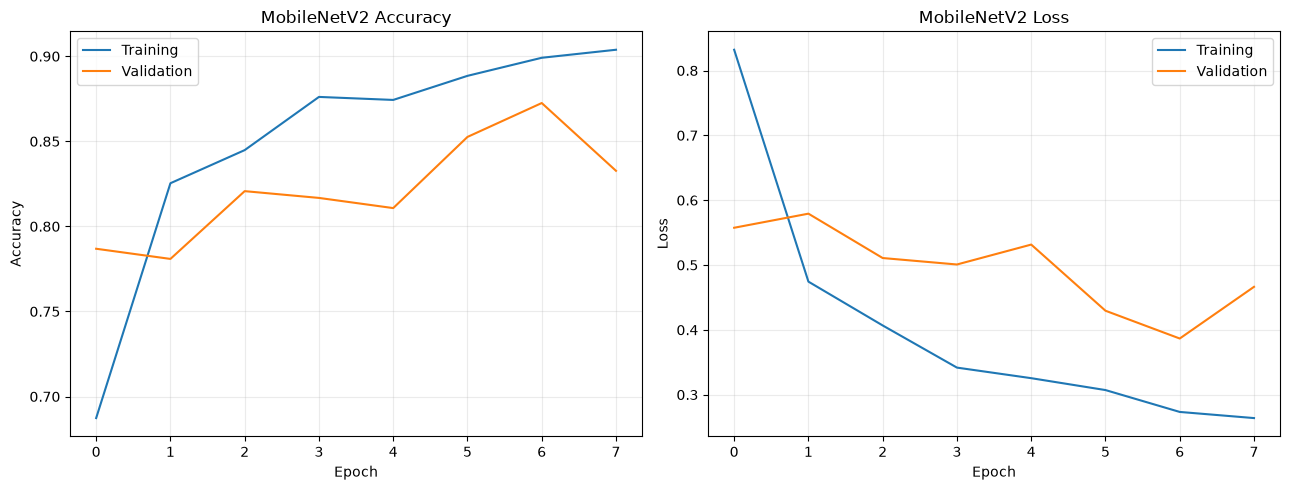

Saved: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\reports\figures\mobilenetv2_training_curves.png


In [9]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("MobileNetV2 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("MobileNetV2 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()

plot_path = FIGURES_DIR / "mobilenetv2_training_curves.png"
fig.savefig(plot_path, dpi=130, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)


32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 213ms/step
              precision    recall  f1-score   support

      glioma     0.9398    0.9689    0.9541       161
  meningioma     0.9121    0.6694    0.7721       124
    no_tumor     0.9101    0.8182    0.8617        99
   pituitary     0.7564    1.0000    0.8613       118

    accuracy                         0.8725       502
   macro avg     0.8796    0.8641    0.8623       502
weighted avg     0.8840    0.8725    0.8691       502



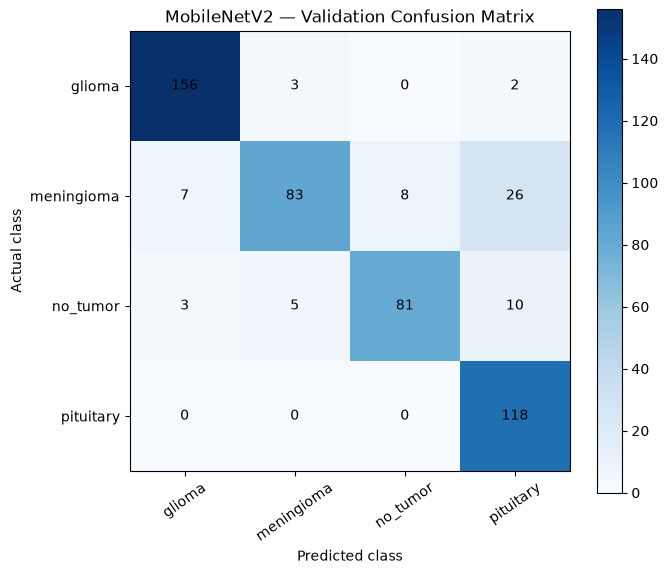

{
  "model": "MobileNetV2",
  "validation_accuracy": 0.8725099601593626,
  "validation_macro_f1": 0.8623093649738749,
  "validation_macro_precision": 0.8795923910483272,
  "validation_macro_recall": 0.8641201890675945,
  "parameters": 2263108
}


In [10]:

best_model = tf.keras.models.load_model(checkpoint_path)

y_true = np.concatenate([
    labels.numpy() for _, labels in valid_ds
])

probabilities = best_model.predict(valid_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES))
)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=35)
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title("MobileNetV2 — Validation Confusion Matrix")

for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")

fig.colorbar(image, ax=ax)
fig.tight_layout()

cm_path = FIGURES_DIR / "mobilenetv2_validation_confusion_matrix.png"
fig.savefig(cm_path, dpi=130, bbox_inches="tight")
plt.show()

results = {
    "model": "MobileNetV2",
    "validation_accuracy": float(np.mean(y_true == y_pred)),
    "validation_macro_f1": float(report["macro avg"]["f1-score"]),
    "validation_macro_precision": float(report["macro avg"]["precision"]),
    "validation_macro_recall": float(report["macro avg"]["recall"]),
    "parameters": int(best_model.count_params())
}

with open(
    REPORTS_DIR / "mobilenetv2_results.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(results, file, indent=2)

print(json.dumps(results, indent=2))


In [11]:

cnn_results_path = REPORTS_DIR / "custom_cnn_results.json"

with open(cnn_results_path, encoding="utf-8") as file:
    cnn_results = json.load(file)

comparison = pd.DataFrame([
    {
        "model": "Custom CNN",
        "validation_accuracy": cnn_results["best_validation_accuracy"],
        "validation_loss": cnn_results["best_validation_loss"],
        "parameters": cnn_results["parameters"]
    },
    {
        "model": "MobileNetV2",
        "validation_accuracy": results["validation_accuracy"],
        "validation_loss": float(np.min(history.history["val_loss"])),
        "parameters": results["parameters"]
    }
])

display(comparison)

comparison.to_csv(
    REPORTS_DIR / "model_comparison.csv",
    index=False
)

print("Saved: reports/model_comparison.csv")


,model,validation_accuracy,validation_loss,parameters
0,Custom CNN,0.733068,0.619248,305380
1,MobileNetV2,0.872510,0.386634,2263108


Saved: reports/model_comparison.csv


In [12]:

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report
)

frozen_path = MODELS_DIR / "mobilenetv2_best.keras"
finetuned_path = MODELS_DIR / "mobilenetv2_finetuned_best.keras"

# Reuse valid_ds from the transfer-learning notebook
y_true = np.concatenate([
    labels.numpy() for _, labels in valid_ds
])

comparison_rows = []

for name, path in [
    ("MobileNetV2 Frozen", frozen_path),
    ("MobileNetV2 Fine-tuned", finetuned_path)
]:
    if not path.exists():
        print(f"Skipping missing model: {path.name}")
        continue

    candidate = tf.keras.models.load_model(path)
    probabilities = candidate.predict(valid_ds, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    print(f"\n{'=' * 55}")
    print(name)
    print(classification_report(
        y_true,
        predictions,
        labels=np.arange(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    ))

    comparison_rows.append({
        "model": name,
        "validation_accuracy": accuracy_score(
            y_true, predictions
        ),
        "macro_f1": f1_score(
            y_true, predictions, average="macro"
        ),
        "macro_recall": recall_score(
            y_true, predictions, average="macro"
        ),
        "meningioma_recall": recall_score(
            y_true,
            predictions,
            labels=[CLASS_NAMES.index("meningioma")],
            average="macro",
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

comparison_df.to_csv(
    REPORTS_DIR / "mobilenetv2_finetuning_comparison.csv",
    index=False
)



MobileNetV2 Frozen
              precision    recall  f1-score   support

      glioma     0.9398    0.9689    0.9541       161
  meningioma     0.9121    0.6694    0.7721       124
    no_tumor     0.9101    0.8182    0.8617        99
   pituitary     0.7564    1.0000    0.8613       118

    accuracy                         0.8725       502
   macro avg     0.8796    0.8641    0.8623       502
weighted avg     0.8840    0.8725    0.8691       502

Skipping missing model: mobilenetv2_finetuned_best.keras


,model,validation_accuracy,macro_f1,macro_recall,meningioma_recall
0,MobileNetV2 Frozen,0.87251,0.862309,0.86412,0.669355


In [13]:

import tensorflow as tf
from tensorflow.keras import layers

# Load the best frozen model
fine_model = tf.keras.models.load_model(
    MODELS_DIR / "mobilenetv2_best.keras"
)

# Find the MobileNetV2 backbone
base_model = next(
    layer for layer in fine_model.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

# Unfreeze the backbone
base_model.trainable = True

# Freeze all except the final 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

fine_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model prepared.")
print(
    "Trainable parameters:",
    sum(
        int(tf.size(w))
        for w in fine_model.trainable_weights
    )
)


Fine-tuning model prepared.
Trainable parameters: 1200004


In [14]:

fine_tune_path = (
    MODELS_DIR / "mobilenetv2_finetuned_best.keras"
)

fine_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(fine_tune_path),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

fine_history = fine_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=8,
    callbacks=fine_callbacks,
    verbose=1
)

print("\nFine-tuning completed.")
print("Model saved:", fine_tune_path)


Epoch 1/8


c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9050 - loss: 0.2703
Epoch 1: val_loss improved from None to 0.36371, saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\mobilenetv2_finetuned_best.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 36s 225ms/step - accuracy: 0.9050 - loss: 0.2703 - val_accuracy: 0.8845 - val_loss: 0.3637 - learning_rate: 1.0000e-05
Epoch 2/8
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.9239 - loss: 0.2173
Epoch 2: val_loss did not improve from 0.36371
106/106 ━━━━━━━━━━━━━━━━━━━━ 23s 216ms/step - accuracy: 0.9239 - loss: 0.2173 - val_accuracy: 0.8665 - val_loss: 0.4099 - learning_rate: 1.0000e-05
Epoch 3/8
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.9251 - loss: 0.1864
Epoch 3: val_loss improved from 0.36371 to 0.33389, saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\mobilenetv